In [8]:
pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.3/13.3 MB 530.7 kB/s eta 0:00:00m eta 0:00:010:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 301.8/301.8 KB 777.1 kB/s eta 0:00:001m782.7 kB/s eta 0:00:01
Note: you may need to restart the kernel to use updated packages.


# Introduction to Scikit-Learn (sklearn)

This notebook demonstrate some of the most useful functions of the beautiful Scikit-Learn library.

What we're going to cover:

0. An end-to-end Scikit-Learn workflow
1. Getting the data ready
2. Choose the right estimator/algorithm for our problems
3. Fit the model/algorithm and use it to make predictions on our data
4. Evaluation a model
5. Improve a model
6. Save and load a trained model
7. Putting it all together!

## 0. An end-to-end Scikit-Learn workflow

In [2]:
# 1. An end-to-end Scikit-Learn workflow
import pandas as pd
import numpy as np
heart_disease = pd.read_csv("heart-disease.csv")
heart_disease

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [62]:
import warnings
warnings.filterwarnings('ignore')
# warnings.filterwarnings("default")

In [4]:
import sklearn
sklearn.show_versions()

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"



System:
    python: 3.10.12 (main, Nov 20 2023, 15:14:05) [GCC 11.4.0]
executable: /usr/bin/python3
   machine: Linux-6.5.0-28-generic-x86_64-with-glibc2.35

Python dependencies:
      sklearn: 1.5.0
          pip: 22.0.2
   setuptools: 59.6.0
        numpy: 1.26.4
        scipy: 1.8.0
       Cython: None
       pandas: 2.2.2
   matplotlib: 3.5.1
       joblib: 1.4.2
threadpoolctl: 3.5.0

Built with OpenMP: True

threadpoolctl info:
       user_api: blas
   internal_api: openblas
    num_threads: 32
         prefix: libopenblas
       filepath: /home/haseebkhan2@ISB.MTBC.COM/.local/lib/python3.10/site-packages/numpy.libs/libopenblas64_p-r0-0cf96a72.3.23.dev.so
        version: 0.3.23.dev
threading_layer: pthreads
   architecture: Sandybridge

       user_api: blas
   internal_api: openblas
    num_threads: 32
         prefix: libopenblas
       filepath: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.20.so
        version: 0.3.20
threading_layer: pthreads
   architecture

In [5]:
# Create X (Feature matrix)
X = heart_disease.drop("target",axis=1)
# Create y (labels)
y = heart_disease["target"]

In [6]:
# Choose the right model and hyperprameters
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier()

#we'll keep the default hyperparameters
clf.get_params()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [7]:
# 3. Fit the model to the training data
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.2)

In [8]:
clf.fit(X_train,y_train);

In [9]:
# make a prediction
# y_label = clf.predict(np.array([0,2,3,4]))
y_preds = clf.predict(X_test)
y_preds

array([0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1,
       0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1,
       0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0])

In [10]:
y_test

175    0
69     1
147    1
247    0
213    0
      ..
200    0
80     1
114    1
232    0
95     1
Name: target, Length: 61, dtype: int64

In [11]:
# Evaluate the model on the training data and test data
clf.score(X_train,y_train)

1.0

In [12]:
clf.score(X_test,y_test)

0.8032786885245902

In [13]:
from sklearn.metrics import classification_report , confusion_matrix ,accuracy_score

print(classification_report(y_test,y_preds))

              precision    recall  f1-score   support

           0       0.81      0.76      0.79        29
           1       0.79      0.84      0.82        32

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



In [14]:
confusion_matrix(y_test, y_preds)

array([[22,  7],
       [ 5, 27]])

In [15]:
accuracy_score(y_test, y_preds)

0.8032786885245902

In [16]:
# 5. Improve a model
# Try different amount of n_estimators
np.random.seed(42)
for i in range(10,100,10):
    print(f"Trying model with {i} estimators...")
    clf = RandomForestClassifier(n_estimators = i).fit(X_train,y_train)
    print(f"Model accuracy on the test set: {clf.score(X_test,y_test) * 100:.2f}%")
    print("")

Trying model with 10 estimators...
Model accuracy on the test set: 77.05%

Trying model with 20 estimators...
Model accuracy on the test set: 77.05%

Trying model with 30 estimators...
Model accuracy on the test set: 75.41%

Trying model with 40 estimators...
Model accuracy on the test set: 77.05%

Trying model with 50 estimators...
Model accuracy on the test set: 78.69%

Trying model with 60 estimators...
Model accuracy on the test set: 78.69%

Trying model with 70 estimators...
Model accuracy on the test set: 81.97%

Trying model with 80 estimators...
Model accuracy on the test set: 80.33%

Trying model with 90 estimators...
Model accuracy on the test set: 80.33%



In [17]:
import pickle
pickle.dump(clf, open("random_forest_model_1.pkl","wb")) 

/tmp/ipykernel_1527401/4007368799.py:2: ResourceWarning: unclosed file <_io.BufferedWriter name='random_forest_model_1.pkl'>
  pickle.dump(clf, open("random_forest_model_1.pkl","wb"))


In [18]:
loaded_model = pickle.load(open("random_forest_model_1.pkl","rb"))
loaded_model.score(X_test,y_test)

/tmp/ipykernel_1527401/859664115.py:1: ResourceWarning: unclosed file <_io.BufferedReader name='random_forest_model_1.pkl'>
  loaded_model = pickle.load(open("random_forest_model_1.pkl","rb"))


0.8032786885245902

In [19]:
what_were_covering = ["0. An end-to-end Scikit-Learn workflow",
"1. Getting the data ready"
,"2. Choose the right estimator/algorithm for our problems"
,"3. Fit the model/algorithm and use it to make predictions on our data"
,"4. Evaluation a model"
,"5. Improve a model"
,"6. Save and load a trained model"
,"7. Putting it all together!"]

In [20]:
what_were_covering

['0. An end-to-end Scikit-Learn workflow',
 '1. Getting the data ready',
 '2. Choose the right estimator/algorithm for our problems',
 '3. Fit the model/algorithm and use it to make predictions on our data',
 '4. Evaluation a model',
 '5. Improve a model',
 '6. Save and load a trained model',
 '7. Putting it all together!']

In [21]:
#standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

## 1. Getting our data ready to be used with machine learning

Three main things we have to do:

    1. Split the data into features and labels (usally "X" & "Y")
    2. Filling (also called imputing) or disregarding missing values
    3. Converting non-numerical values to numerical values(also callled feature encoding)

In [22]:
X = heart_disease.drop("target", axis=1)
X.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2


In [23]:
y = heart_disease["target"]
y.head()

0    1
1    1
2    1
3    1
4    1
Name: target, dtype: int64

In [24]:
#Split the data into training and test sets
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

In [25]:
X_train.shape,X_test.shape, y_test.shape,y_train.shape

((242, 13), (61, 13), (61,), (242,))

## 1.1 Make sure it's all numerical

In [26]:
car_sales = pd.read_csv("car-sales-extended.csv")

In [27]:
car_sales.head()

,Make,Colour,Odometer (KM),Doors,Price
0,Honda,White,35431,4,15323
1,BMW,Blue,192714,5,19943
2,Honda,White,84714,4,28343
3,Toyota,White,154365,4,13434
4,Nissan,Blue,181577,3,14043


In [28]:
car_sales.dtypes

Make             object
Colour           object
Odometer (KM)     int64
Doors             int64
Price             int64
dtype: object

In [29]:
#split into X/y
X = car_sales.drop("Price", axis=1)
y = car_sales["Price"]

#Split into training and test
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2)

In [40]:
# Build ML model
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor()
# model.fit(X_train,y_train)
# model.score()

In [41]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorial_features = ['Make',"Colour", "Doors"]
one_hot = OneHotEncoder()
transformer = ColumnTransformer([("one_hot",one_hot,categorial_features)],remainder = 'passthrough')
transformed_X = transformer.fit_transform(X)
transformed_X

array([[0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        0.00000e+00, 3.54310e+04],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 0.00000e+00,
        1.00000e+00, 1.92714e+05],
       [0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        0.00000e+00, 8.47140e+04],
       ...,
       [0.00000e+00, 0.00000e+00, 1.00000e+00, ..., 1.00000e+00,
        0.00000e+00, 6.66040e+04],
       [0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        0.00000e+00, 2.15883e+05],
       [0.00000e+00, 0.00000e+00, 0.00000e+00, ..., 1.00000e+00,
        0.00000e+00, 2.48360e+05]])

In [42]:
X.head()

,Make,Colour,Odometer (KM),Doors
0,Honda,White,35431,4
1,BMW,Blue,192714,5
2,Honda,White,84714,4
3,Toyota,White,154365,4
4,Nissan,Blue,181577,3


In [43]:
pd.DataFrame(transformed_X)

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,35431.0
1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,192714.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,84714.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,154365.0
4,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,181577.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,35820.0
996,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,155144.0
997,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,66604.0
998,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,215883.0


In [44]:
X['Make'].value_counts()

Make
Toyota    398
Honda     304
Nissan    198
BMW       100
Name: count, dtype: int64

In [45]:
dummies = pd.get_dummies(car_sales[["Make",'Colour','Doors']],dtype=int)
dummies

,Doors,Make_BMW,Make_Honda,Make_Nissan,Make_Toyota,Colour_Black,Colour_Blue,Colour_Green,Colour_Red,Colour_White
0,4,0,1,0,0,0,0,0,0,1
1,5,1,0,0,0,0,1,0,0,0
2,4,0,1,0,0,0,0,0,0,1
3,4,0,0,0,1,0,0,0,0,1
4,3,0,0,1,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...
995,4,0,0,0,1,1,0,0,0,0
996,3,0,0,1,0,0,0,0,0,1
997,4,0,0,1,0,0,1,0,0,0
998,4,0,1,0,0,0,0,0,0,1


In [46]:
np.random.seed(42)
X_train, X_test, y_train,y_test = train_test_split(transformed_X,y, test_size=0.2)

In [47]:
model.fit(X_train,y_train);

In [48]:
model.score(X_test,y_test)

0.3235867221569877

In [ ]:
print(sklearn.__version__)

In [38]:
# class person:
#     def __init__(self,name='Haseeb',height=176,colour='black'):
#         self.name = name
#         self.height = height
#         self.hair_colour = colour
#     def height_in_inches(self):
#         inches = self.height/2.54
#         return inches


# class school(person):
#     def __init__(self,school_name,class_name,name,height=176,colour='black'):
#         super().__init__(name,height,colour)
#         self.school_name = school_name
#         self.class_name = class_name
#         self.height = self.height_in_inches()
#     def addmission(self):
#         return f'{self.name.title()} you got admission in {self.school_name}, in class {self.class_name}, You got {self.hair_colour} hairs and your height is {self.height:.2f} inches'
        

# peson_instance = person()
# x = peson_instance.height_in_inches()
# x
# school_instance = school('BGS','8th',"haseeb")
# y = school_instance.addmission()
# y

### 1.2 What if there were missing values?

1. Fill them some value (also known as imputation).
2. Remove the samples with missing data altogether.

In [49]:
# import car sales missing data
car_sales_missing = pd.read_csv("car-sales-extended-missing-data.csv")
car_sales_missing.head()

,Make,Colour,Odometer (KM),Doors,Price
0,Honda,White,35431.0,4.0,15323.0
1,BMW,Blue,192714.0,5.0,19943.0
2,Honda,White,84714.0,4.0,28343.0
3,Toyota,White,154365.0,4.0,13434.0
4,Nissan,Blue,181577.0,3.0,14043.0


In [52]:
car_sales_missing.isna().sum()

Make             49
Colour           50
Odometer (KM)    50
Doors            50
Price            50
dtype: int64

In [54]:
# Create X nad y
X = car_sales_missing.drop("Price", axis=1)
y = car_sales_missing["Price"]

In [67]:
#lets try and convert our data inito numbers
# Turn the categories into numbers
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_feature = ["Male","Colour","Door"]
one_hot = OneHotEncoder()
transformer = ColumnTransformer([("one_hot",one_hot,categorial_features)],remainder="passthrough")

transformed_X = transformer.fit_transform(X)
transformed_X

<1000x16 sparse matrix of type '<class 'numpy.float64'>'
	with 4000 stored elements in Compressed Sparse Row format>

### Option 1: Fill missing data with pandas

In [68]:
# Fill the "Make" column
car_sales_missing["Make"].fillna("missing", inplace = True)

# Fill the "Colour" column
car_sales_missing['Colour'].fillna('missing', inplace = True)

# Fill the "Odometer (KM)" column
car_sales_missing['Odometer (KM)'].fillna(car_sales_missing['Odometer (KM)'].mean(), inplace=True)

# Fill the "Doors" column
car_sales_missing['Doors'].fillna(4, inplace = True)

In [69]:
car_sales_missing.isna().sum()

Make             0
Colour           0
Odometer (KM)    0
Doors            0
Price            0
dtype: int64

In [70]:
# remove rows with missing Price value
car_sales_missing.dropna(inplace=True)

In [71]:
car_sales_missing.isna().sum()

Make             0
Colour           0
Odometer (KM)    0
Doors            0
Price            0
dtype: int64

In [72]:
car_sales_missing['Doors'].value_counts()

Doors
4.0    815
5.0     71
3.0     64
Name: count, dtype: int64

In [73]:
X = car_sales_missing.drop('Price',axis=1)
y = car_sales_missing['Price']

In [76]:
#lets try and convert our data inito numbers
# Turn the categories into numbers
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_feature = ["Male","Colour","Door"]
one_hot = OneHotEncoder()
transformer = ColumnTransformer([("one_hot",one_hot,categorial_features)],remainder="passthrough")

transformed_X = transformer.fit_transform(X)
transformed_X

<950x15 sparse matrix of type '<class 'numpy.float64'>'
	with 3800 stored elements in Compressed Sparse Row format>

### Option 2: Fill missing values with Scikit-Learn

1.Feature Scaling with scikit-learn
    In this post we explore 3 methods of feature scaling that are implemented in scikit-learn:

    StandardScaler
    MinMaxScaler
    RobustScaler
    Normalizer


    Standard Scaler
        The StandardScaler assumes your data is normally distributed within each feature and will scale them such that the distribution is now centred around 0, with a standard deviation of 1.
        
        The mean and standard deviation are calculated for the feature and then the feature is scaled based on:
        
        xi–mean(x)/stdev(x)
        If data is not normally distributed, this is not the best scaler to use.


    Min-Max Scaler
        The MinMaxScaler is the probably the most famous scaling algorithm, and follows the following formula for each feature:
        
        xi–min(x)/max(x)–min(x)
        It essentially shrinks the range such that the range is now between 0 and 1 (or -1 to 1 if there are negative values).
        
        This scaler works better for cases in which the standard scaler might not work so well. If the distribution is not Gaussian or the standard deviation is very small, the min-max scaler works better.
        
        However, it is sensitive to outliers, so if there are outliers in the data, you might want to consider the Robust Scaler below.

    Robust Scaler
        The RobustScaler uses a similar method to the Min-Max scaler but it instead uses the interquartile range, rathar than the min-max, so that it is robust to outliers. Therefore it follows the formula:
        
        xi–Q1(x)/Q3(x)–Q1(x)
        For each feature.
        
        Of course this means it is using the less of the data for scaling so it’s more suitable for when there are outliers in the data.

    Normalizer
        The normalizer scales each value by dividing each value by its magnitude in n
        -dimensional space for n
         number of features.
        
        Say your features were x, y and z Cartesian co-ordinates your scaled value for x would be:
        
        xi/√x**2i+y**2i+z**2i
        Each point is now within 1 unit of the origin on this Cartesian co-ordinate system.

In [81]:
car_sales_missing = pd.read_csv("car-sales-extended-missing-data.csv")
car_sales_missing.head()

,Make,Colour,Odometer (KM),Doors,Price
0,Honda,White,35431.0,4.0,15323.0
1,BMW,Blue,192714.0,5.0,19943.0
2,Honda,White,84714.0,4.0,28343.0
3,Toyota,White,154365.0,4.0,13434.0
4,Nissan,Blue,181577.0,3.0,14043.0


In [82]:
car_sales_missing.isna().sum()

Make             49
Colour           50
Odometer (KM)    50
Doors            50
Price            50
dtype: int64

In [83]:
car_sales_missing.dropna(subset = ["Price"], inplace=True)

In [84]:
car_sales_missing.isna().sum()

Make             47
Colour           46
Odometer (KM)    48
Doors            47
Price             0
dtype: int64

In [85]:
#split into X & y
X = car_sales_missing.drop('Price',axis=1)
y = car_sales_missing['Price']

In [93]:
# Fill missing values with Scikit-Learn
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

# fill categorical values with "Missing" & numerical values with mean
cat_imputer = SimpleImputer(strategy='constant',fill_value='missing')
door_imputer = SimpleImputer(strategy='constant', fill_value=4)
num_imputer = SimpleImputer(strategy='mean')

# Define columns
cat_features = ['Make', 'Colour']
door_feature = ['Doors']
num_feature = ['Odometer (KM)']

# Create and imputer (Something that fills missing data)
imputer = ColumnTransformer([('cat_imputer', cat_imputer,cat_features),
                            ('door_imputer',door_imputer,door_feature),
                            ('num_feature', num_imputer,num_feature)])
# Transform the data
filled_X = imputer.fit_transform(X)
filled_X

array([['Honda', 'White', 4.0, 35431.0],
       ['BMW', 'Blue', 5.0, 192714.0],
       ['Honda', 'White', 4.0, 84714.0],
       ...,
       ['Nissan', 'Blue', 4.0, 66604.0],
       ['Honda', 'White', 4.0, 215883.0],
       ['Toyota', 'Blue', 4.0, 248360.0]], dtype=object)

In [95]:
# filled_X= pd.DataFrame(filled_X)    #testing

In [94]:
# filled_X.isna().sum()   #testing

In [96]:
car_sales_filled = pd.DataFrame(filled_X, columns=['Make','Colour','Doors','Odometer (KM)'])

In [97]:
car_sales_filled.head()

,Make,Colour,Doors,Odometer (KM)
0,Honda,White,4.0,35431.0
1,BMW,Blue,5.0,192714.0
2,Honda,White,4.0,84714.0
3,Toyota,White,4.0,154365.0
4,Nissan,Blue,3.0,181577.0


In [98]:
# Lets try and convert our data into numbers
# Turns the categories into numbers
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

categorical_features = ['Make','Colour','Doors']
one_hot = OneHotEncoder()
transformer = ColumnTransformer([('one_hot',one_hot,categorical_features)],
                               remainder='passthrough')

transformed_X = transformer.fit_transform(car_sales_filled)
transformed_X

<950x15 sparse matrix of type '<class 'numpy.float64'>'
	with 3800 stored elements in Compressed Sparse Row format>

In [101]:
# Now we got our data as number and filled (no missing values)
# let's fit a model
np.random.seed(42)
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(transformed_X,y,test_size=0.2)

model = RandomForestRegressor()
model.fit(X_train,y_train)
model.score(X_test,y_test)

0.21990196728583944

In [102]:
len(car_sales_filled), len(car_sales)

(950, 1000)

## 2. Choosing the right estimator/algorithm for your problem

### 2.1 Picking a ML model for a regression problem

In [121]:
# Get California Housing dataset
from sklearn.datasets import fetch_california_housing
housing =  fetch_california_housing()
housing

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]]),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894]),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': '.. _california_housing_dataset:\n

In [122]:
housing_df = pd.DataFrame(housing['data'], columns=housing['feature_names'])
housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [123]:
housing_df['target'] = housing['target']

In [125]:
# housing_df = housing_df.drop('MedHouseVal',axis=1)

In [126]:
housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [127]:
# import alogorithm/estimator
from sklearn.linear_model import Ridge

#setup random seed
np.random.seed(42)

# Create the data
X = housing_df.drop('target', axis=1)
y = housing_df['target']  # median house price in $100,000s

# Split into train and test sets
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

# Instantiate and fit the model (on the training set)
model = Ridge()
model.fit(X_train,y_train)


#check the score of the model (on the set)
model.score(X_test,y_test)

0.575854961144012

What if `Ridge` didn't work or the score didn't fit our needs?

Well, we could always try a different model...

How about we try an ensamble model (an ensamble is combination of samller models to try and make better prediction than just a single model)?

Sklearn's ensamble models can be found here: https://scikit-learn.org/stable/modules/ensemble.html

In [130]:
# import the randomForestRegressor model calss from the ensemble module
from sklearn.ensemble import RandomForestClassifier

np.random.seed(42)

X = housing_df.drop('target',axis=1)
y = housing_df['target']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

model = RandomForestRegressor()
model.fit(X_train,y_train)

model.score(X_test,y_test)

0.8066196804802649

## 2.2 Picking a machine learning model for a classification problem

In [131]:
heart_disease = pd.read_csv('heart-disease.csv')
heart_disease.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [138]:
#import the linearSVC estimator class
from sklearn.svm import LinearSVC

#setup random seed
np.random.seed(42)

#make the data
X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

#split the data

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#initiate LinearSVC
clf = LinearSVC(max_iter = 10000)
clf.fit(X_train,y_train)

# Evaluate the linearSVC
clf.score(X_test,y_test)

0.8688524590163934

In [136]:
#import the RandomForestClassifier estimator class
from sklearn.ensemble import RandomForestClassifier

#setup random seed
np.random.seed(42)

#make the data
X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

#split the data

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#initiate RandomForestClassifier
clf = RandomForestClassifier()
clf.fit(X_train,y_train)

# Evaluate the RandomForestClassifier
clf.score(X_test,y_test)

0.8524590163934426

### Tidbit:

    1. If you have structured data , used ensemble methods
    2. If you have unstructured data, use deep-learning or transfer learning

## 3. Fit the model/algorithm on our data and use it to make predictions

### 3.1 Fitting the model to the data

* `X` = features, features variables, data
* `y` = labels, target, target variables

In [140]:
#import the RandomForestClassifier estimator class
from sklearn.ensemble import RandomForestClassifier

#setup random seed
np.random.seed(42)

#make the data
X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

#split the data

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#initiate RandomForestClassifier
clf = RandomForestClassifier(n_estimators=100)

#Fit the model to the data
clf.fit(X_train,y_train)

# Evaluate the RandomForestClassifier
clf.score(X_test,y_test)

0.8524590163934426

### 3.2 Make a prediction using a machine learning model

2 ways to make predictions:
* 1. `predict()`
* 2. `predict_proba()`

In [142]:
# Use a trained model to make predictions
clf.predict(X_test)

array([0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0])

In [143]:
np.array(y_test)

array([0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0])

In [144]:
# Compare predictions to truth lables to evaluate model
y_preds = clf.predict(X_test)
np.mean(y_preds == y_test)

0.8524590163934426

In [145]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_preds)

0.8524590163934426

### Make predictions with `predict_proba()`


In [148]:
clf.predict_proba(X_test[:5])

array([[0.89, 0.11],
       [0.49, 0.51],
       [0.43, 0.57],
       [0.84, 0.16],
       [0.18, 0.82]])

In [149]:
# lets predict() on the same data...
clf.predict(X_test[:5])

array([0, 1, 1, 0, 1])

`predict()` can also be used for regression models

In [150]:
housing_df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [151]:
from sklearn.ensemble import RandomForestRegressor
np.random.seed(42)

# create the data
X = housing_df.drop('target',axis=1)
y = housing_df['target']

# split into training and test data sets
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#create model instance
model = RandomForestRegressor()

# fit the model to the data
model.fit(X_train, y_train)

# Make predictions
y_preds = model.predict(X_test)

In [152]:
y_preds[:10]

array([0.49384  , 0.75494  , 4.9285964, 2.54029  , 2.33176  , 1.6549701,
       2.34323  , 1.66182  , 2.47489  , 4.8344779])

In [154]:
np.array(y_test[:10])

array([0.477  , 0.458  , 5.00001, 2.186  , 2.78   , 1.587  , 1.982  ,
       1.575  , 3.4    , 4.466  ])

In [157]:
# compare the predictions to the truth
from sklearn.metrics import mean_absolute_error
mean_absolute_error(y_test,y_preds)

0.3265721842781009

In [158]:
housing_df['target']

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: target, Length: 20640, dtype: float64

## 4. Evaluating a machine learning model

Three ways to evaluate Scikit_learn models/estimators:
1. Estimator's built-in `score()` method
2. the `scoring` parameter
3. Problem-specific metric functions

### 4.1 Evaluating a model with the `score` mehtod

In [174]:
from sklearn.ensemble import RandomForestClassifier
np.random.seed(42)
X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

clf = RandomForestClassifier(n_estimators=1000)
clf.fit(X_train,y_train)

RandomForestClassifier(n_estimators=1000)

In [175]:
clf.score(X_test,y_test)

0.8688524590163934

Lets use the `score()` on our regression problem

In [185]:
from sklearn.ensemble import RandomForestRegressor
np.random.seed(42)

# create the data
X = housing_df.drop('target',axis=1)
y = housing_df['target']

# split into training and test data sets
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#create model instance
model = RandomForestRegressor(n_estimators=100)

# fit the model to the data
model.fit(X_train, y_train)

# Make predictions
# y_preds = model.predict(X_test)

RandomForestRegressor()

In [186]:
# The default score() evaluation metric is r_squared for regression algorithms
# Highest = 1.0, lowest = 0.0
model.score(X_test,y_test)

0.8066196804802649

# 4.2 Evaluating a model using the `scoring` parameter

In [188]:
from sklearn.model_selection import cross_val_score

#import the RandomForestClassifier estimator class
from sklearn.ensemble import RandomForestClassifier

#setup random seed
np.random.seed(42)

#make the data
X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

#split the data

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)

#initiate RandomForestClassifier
clf = RandomForestClassifier(n_estimators=100)

#Fit the model to the data
clf.fit(X_train,y_train)

# Evaluate the RandomForestClassifier
clf.score(X_test,y_test)

0.8524590163934426

In [194]:
# Cross-Validation
cross_val_score(clf,X,y,cv=5)

array([0.80327869, 0.90163934, 0.81967213, 0.81666667, 0.76666667])

In [195]:
np.random.seed(42)

#single training and test split score
clf_single_score = clf.score(X_test, y_test)

# Take the mran of 5-fold cross-validation score
clf_cross_val_score = np.mean(cross_val_score(clf,X,y,cv=5))

# Compare the two
clf_single_score , clf_cross_val_score

(0.8524590163934426, 0.8248087431693989)

In [ ]:
# Default scoring parameter of classifier = mean accuracy
clf.score()

In [196]:
# Scoring parameter set to None by default
cross_val_score(clf,X,y,cv=5,scoring=None)


array([0.78688525, 0.86885246, 0.80327869, 0.78333333, 0.76666667])

### 4.2.1 Classification model evaluation metrics

1. Accuracy
2. Are under ROC curve
3. Confusion matrix
4. Classification report

**Accuracy**

In [203]:
heart_disease.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [200]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

np.random.seed(42)

X = heart_disease.drop('target',axis=1)
y = heart_disease['target']

# X_train,X_test,y_train,y_test = train_test_split(X,y, test_size=0.2)

clf = RandomForestClassifier(n_estimators=100)
cross_val_score = cross_val_score(clf,X,y,cv=5)

In [201]:
np.mean(cross_val_score)

0.8248087431693989

In [202]:
print(f"Heart Disease Classifier Cross-Validated Accuracy: {np.mean(cross_val_score) * 100:.2f}%")

Heart Disease Classifier Cross-Validated Accuracy: 82.48%


**Area under the receiver operating characteristic curve (AUC/ROC)**
* Area under curve (AUC)
* ROC curve

ROC curves are a comparison of a model's true positve rate (tpr) versus a  models false positive rate (fpr).

* True positive = model predicts 1 when truth is 1
* False positive = model predicts 1 when truth is 0
* True negative = model predicts 0 when truth is 0
* False negative =  model predicts 0 when truth is 1

In [207]:
from sklearn.metrics import roc_curve
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2)
# Mkae predictions with probabilities
clf.fit(X_train,y_train)
y_probs = clf.predict_proba(X_test)

y_probs[:10], len(y_probs)

(array([[0.83, 0.17],
        [0.55, 0.45],
        [0.91, 0.09],
        [0.03, 0.97],
        [0.13, 0.87],
        [0.05, 0.95],
        [0.39, 0.61],
        [0.82, 0.18],
        [0.01, 0.99],
        [0.53, 0.47]]),
 61)

In [208]:
y_probs_positives = y_probs[:,1]
y_probs_positives[:10]

array([0.17, 0.45, 0.09, 0.97, 0.87, 0.95, 0.61, 0.18, 0.99, 0.47])

In [209]:
# calculate fpr, tpr and thresholds
fpr,tpr, thresholds = roc_curve(y_test,y_probs_positives)

# check the false positive rates
fpr

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.03846154, 0.03846154, 0.11538462, 0.11538462,
       0.11538462, 0.11538462, 0.15384615, 0.19230769, 0.19230769,
       0.19230769, 0.23076923, 0.42307692, 0.5       , 0.53846154,
       0.53846154, 0.65384615, 0.65384615, 0.73076923, 0.80769231,
       0.88461538, 0.96153846, 1.        ])

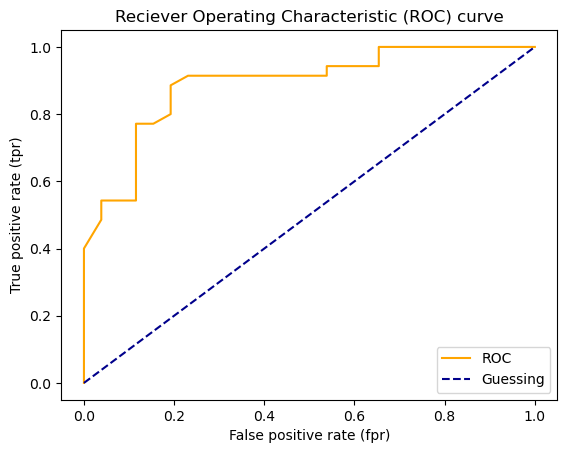

In [211]:
# Create a function fro plotting ROC curves
import matplotlib.pyplot as plt

def plot_roc_curve(fpr,tpr):
    """
    Plots a ROC curve given the fpr and tpr of a model.
    """
    # plot roc curve
    plt.plot(fpr,tpr,color="orange", label='ROC')
    # Plot line with no predictive power (baseline)
    plt.plot([0,1],[0,1], color = 'darkblue', linestyle='--', label="Guessing")

    # Customze the plot
    plt.xlabel('False positive rate (fpr)')
    plt.ylabel('True positive rate (tpr)')
    plt.title("Reciever Operating Characteristic (ROC) curve")
    plt.legend()
    plt.show()

plot_roc_curve(fpr,tpr)

In [212]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_test, y_probs_positives)

0.8895604395604395

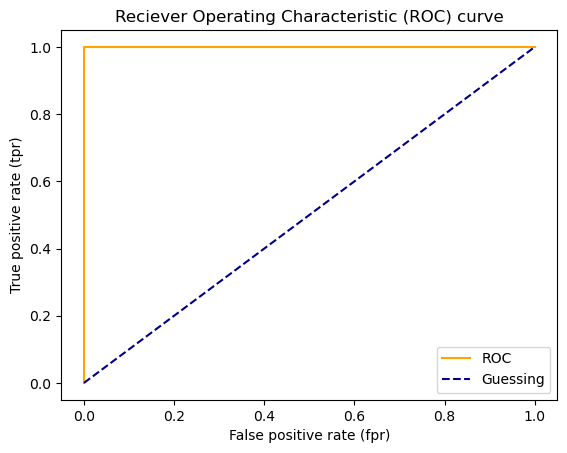

In [216]:
# plot perfect ROC curve and AUC score
fpr,tpr,thresholds = roc_curve(y_test,y_test)
plot_roc_curve(fpr,tpr)

In [214]:
# perfect AUC score
roc_auc_score(y_test,y_test)

1.0

**Confusion Matrix**

A confusion matrix is a quick way to compare the labels a model predicts and the actual labels it was supposed t predict.

In Essence, giving you an idea of where the model is getting confused.

**NEW**

The next way to evaluate a classification model is by using confusion matrix.

A confusion matrix is a quick way to compare the labels a model predicts and the actual labels it was supposed to predicts and the actual label it was supposed to predict.

In essence, this gives you an idea of where the model is getting confused.

In [217]:
from sklearn.metrics import confusion_matrix
y_preds = clf.predict(X_test)

confusion_matrix(y_test,y_preds)

array([[21,  5],
       [ 7, 28]])

In [218]:
# Visualize confusion matrix with pd.crosstab()

pd.crosstab(y_test,y_preds,rownames=['Actual Labels'],
           colnames=["Predicted Labels"])

Predicted Labels,0,1
Actual Labels,,
0,21,5
1,7,28


In [219]:
len(y_preds)

61

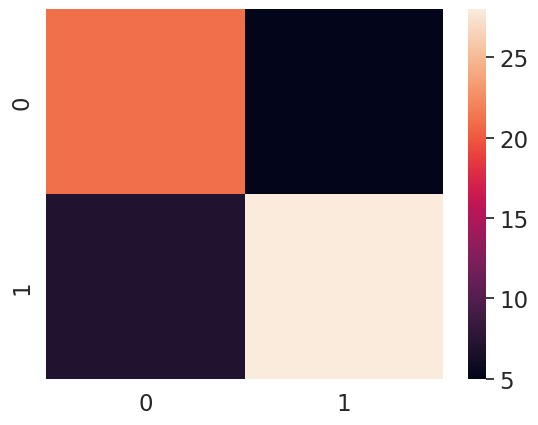

In [220]:
# Make our confusion matrix more visual with Seaborn's heatmap()
import seaborn as sns

sns.set(font_scale=1.5)

conf_mat = confusion_matrix(y_test,y_preds)

sns.heatmap(conf_mat);

**NEW starts from here**

In [237]:
from sklearn.metrics import confusion_matrix
y_preds = clf.predict(X_test)

confusion_matrix(y_test,y_preds)

array([[21,  5],
       [ 7, 28]])

In [249]:
a = [10,2,5,7]
b = []
for i in a:
    i = str(i)
    b.append(i)
b = sorted(b,reverse=True)
x = ''.join(b)


In [250]:
x

'75210'